# The Towpath: café and store analysis

**Question from the owner (Gwen):** *"The café feels busy but the shop feels quiet. Am I imagining it, and what should I do about it?"*

This notebook reads the cleaned workbook (`data/clean/towpath_powerbi_data.xlsx`, the same file the Power BI dashboard uses) and works through that question:

1. Headline numbers (checked against the dashboard)
2. Café vs Store
3. Store investigation: when did customers drop, and was it the price rise?
4. Margin and supplier costs
5. Café operations: busy hours and staffing
6. Wastage
7. Weather and seasons
8. Outliers and basket analysis

The data is fictional and was generated for training. The methods are the point.

In [1]:
from pathlib import Path
import itertools

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA = ROOT / "data" / "clean" / "towpath_powerbi_data.xlsx"
FIG = ROOT / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

CAFE, STORE, GREY = "#1F4E79", "#C8792B", "#A6A6A6"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})
pd.options.display.float_format = "{:,.2f}".format

t = pd.read_excel(DATA, sheet_name=None)
sales, products, staff, shifts = t["Sales"], t["Products"], t["Staff"], t["Shifts"]
wastage, suppliers, purchases, date = t["Wastage"], t["Suppliers"], t["Purchases"], t["Date"]
{name: len(df) for name, df in t.items()}

{'Sales': 76856, 'Products': 40, 'Staff': 10, 'Shifts': 3342, 'Wastage': 5003, 'Suppliers': 6, 'Purchases': 4183, 'Date': 731, 'Cleaning_Log': 23}

## 1. Headline numbers

One wide table (`f`) joins each sales line to its product and date. Six lines with a quantity over 10 (for example 200 butters on one till line) were flagged `Suspicious` during cleaning. They are left out of every figure here, exactly as in the Power BI measures. Refunds (negative quantity) stay in revenue, because they are real money going back out, but a receipt only counts as a customer if it has a normal sale line.

In [2]:
f = (sales[sales["line_type"] != "Suspicious"]
     .merge(products, on="product_id", how="left")
     .merge(date, left_on="date", right_on="Date", how="left"))
f["revenue"] = f["quantity"] * f["unit_price"]
f["cost"] = f["quantity"] * f["unit_cost"]
f["profit"] = f["revenue"] - f["cost"]
# A customer = one receipt with at least one normal "Sale" line (same rule as the Total Customers measure)
f["customer_id"] = f["transaction_id"].where(f["line_type"] == "Sale")

kpi = f.groupby("Year").agg(revenue=("revenue", "sum"), cost=("cost", "sum"),
                            customers=("customer_id", "nunique"))
kpi["gross_margin_%"] = (kpi["revenue"] - kpi["cost"]) / kpi["revenue"] * 100
kpi["avg_spend"] = kpi["revenue"] / kpi["customers"]
kpi["revenue_yoy_%"] = kpi["revenue"].pct_change() * 100
kpi

,revenue,cost,customers,gross_margin_%,avg_spend,revenue_yoy_%
Year,,,,,,
2024,"133,993.94","44,008.53",20832,67.16,6.43,NaN
2025,"141,003.50","46,609.17",20890,66.94,6.75,5.23


**Dashboard check.** With 2025 selected, the Power BI Overview page shows £141,004 revenue, +5.2% on last year and a 66.9% gross margin. The table above gives the same three numbers, so Python and Power BI agree.

Overall the business grew. The next section shows that this total hides two very different stories.

## 2. Café vs Store

In [3]:
area = f.groupby(["business_area", "Year"]).agg(revenue=("revenue", "sum"), cost=("cost", "sum"),
                                                customers=("customer_id", "nunique")).unstack("Year")
split = pd.DataFrame({
    "revenue_2024": area[("revenue", 2024)], "revenue_2025": area[("revenue", 2025)],
    "revenue_yoy_%": (area[("revenue", 2025)] / area[("revenue", 2024)] - 1) * 100,
    "customers_2024": area[("customers", 2024)], "customers_2025": area[("customers", 2025)],
    "customers_yoy_%": (area[("customers", 2025)] / area[("customers", 2024)] - 1) * 100,
    "margin_2024_%": (1 - area[("cost", 2024)] / area[("revenue", 2024)]) * 100,
    "margin_2025_%": (1 - area[("cost", 2025)] / area[("revenue", 2025)]) * 100,
})
split

,revenue_2024,revenue_2025,revenue_yoy_%,customers_2024,customers_2025,customers_yoy_%,margin_2024_%,margin_2025_%
business_area,,,,,,,,
Café,"87,307.80","98,175.55",12.45,10215,11437,11.96,79.02,77.33
Store,"46,686.14","42,827.95",-8.26,10617,9453,-10.96,44.96,43.15


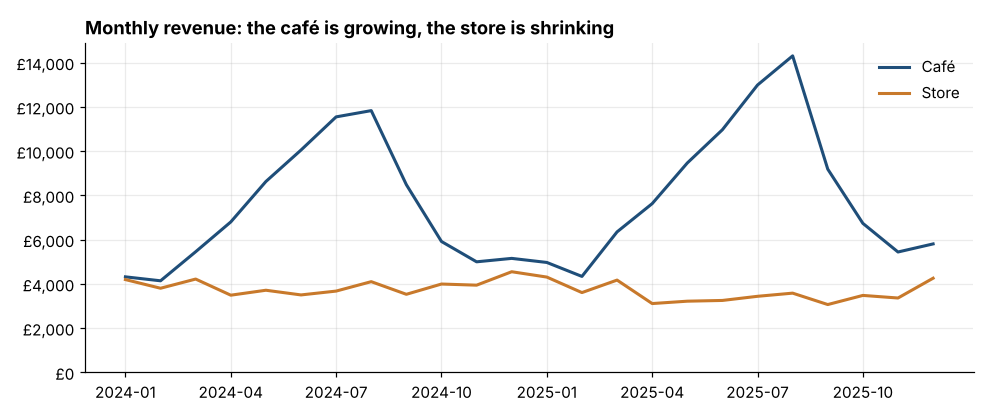

In [4]:
monthly = f.groupby(["YearMonth", "business_area"])["revenue"].sum().unstack()
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(monthly.index, monthly["Café"], color=CAFE, lw=2, label="Café")
ax.plot(monthly.index, monthly["Store"], color=STORE, lw=2, label="Store")
ax.set_title("Monthly revenue: the café is growing, the store is shrinking")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("£{x:,.0f}"))
ax.set_xticks(monthly.index[::3]); ax.set_ylim(0); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "01_monthly_revenue_by_area.png", dpi=160); plt.show()

Gwen is not imagining it. Café revenue is up 12.4% and store revenue is down 8.3%. Store revenue fell because fewer people came in (customers down 11.0%), not because each customer spent less.

## 3. Store investigation

### 3.1 When did the customers go?

In [5]:
store = f[f["business_area"] == "Store"]
cust_m = store.groupby(["MonthNo", "Month", "Year"])["customer_id"].nunique().unstack("Year")
cust_m["yoy_%"] = (cust_m[2025] / cust_m[2024] - 1) * 100
cust_m

,Year,2024,2025,yoy_%
MonthNo,Month,,,
1,Jan,800,770,-3.75
2,Feb,711,662,-6.89
3,Mar,848,856,0.94
4,Apr,866,743,-14.20
5,May,936,818,-12.61
6,Jun,962,807,-16.11
7,Jul,1042,920,-11.71
8,Aug,1053,907,-13.87
9,Sep,880,777,-11.70


Jan-Mar: -3.0%    Apr-Dec: -13.2%


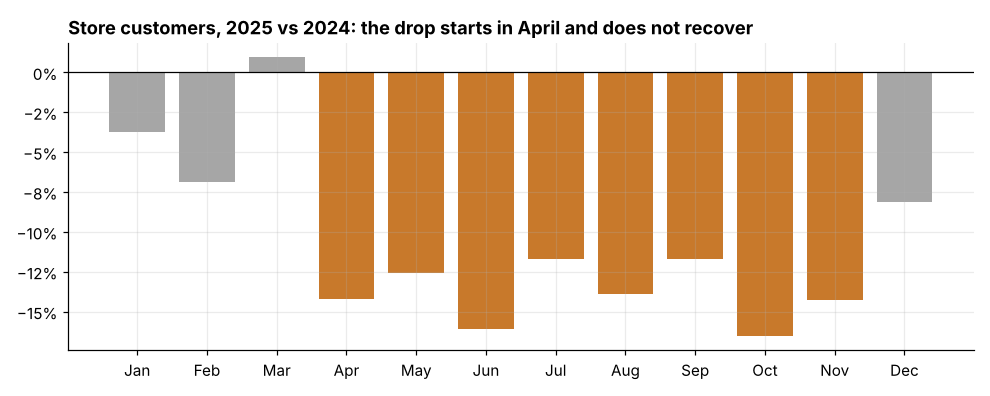

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.6))
m = cust_m.reset_index()
colors = [STORE if v < -10 else GREY for v in m["yoy_%"]]
ax.bar(m["Month"], m["yoy_%"], color=colors)
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Store customers, 2025 vs 2024: the drop starts in April and does not recover")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
fig.tight_layout(); fig.savefig(FIG / "02_store_customers_yoy_by_month.png", dpi=160); plt.show()

q1 = cust_m.loc[cust_m.index.get_level_values("MonthNo") <= 3, [2024, 2025]].sum()
rest = cust_m.loc[cust_m.index.get_level_values("MonthNo") >= 4, [2024, 2025]].sum()
print(f"Jan-Mar: {q1[2025] / q1[2024] - 1:+.1%}    Apr-Dec: {rest[2025] / rest[2024] - 1:+.1%}")

January to March 2025 was close to the year before. From April onwards the store runs 8% to 16% below 2024 every single month. A weekly view pins down the timing.

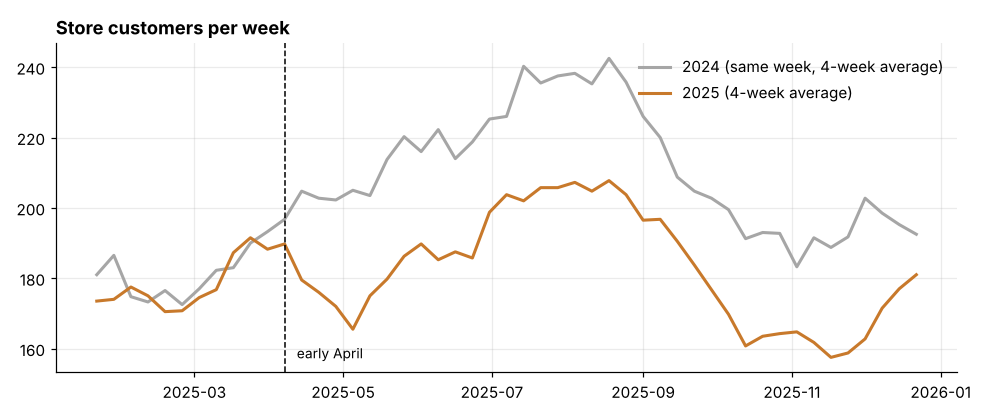

,2025,2024,yoy_%,yoy_4wk_avg_%
WeekStart,,,,
2025-03-03,202,186,8.60,-1.50
2025-03-10,172,201,-14.40,-2.70
2025-03-17,202,176,14.80,2.80
2025-03-24,190,197,-3.60,1.30
2025-03-31,189,199,-5.00,-2.10
2025-04-07,178,215,-17.20,-2.80
2025-04-14,161,208,-22.60,-12.10
2025-04-21,176,189,-6.90,-12.90
2025-04-28,173,197,-12.20,-14.70


In [7]:
wk = store.groupby("WeekStart")["customer_id"].nunique()
wk = wk[(wk.index >= "2024-01-01") & (wk.index <= "2025-12-22")]           # full weeks only
this_year = wk[wk.index >= "2024-12-30"]
last_year = wk.reindex(this_year.index - pd.Timedelta(weeks=52))
cmp = pd.DataFrame({"2025": this_year.values, "2024": last_year.values}, index=this_year.index)
cmp["yoy_%"] = (cmp["2025"] / cmp["2024"] - 1) * 100
cmp["yoy_4wk_avg_%"] = cmp["yoy_%"].rolling(4).mean()

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(cmp.index, cmp["2024"].rolling(4).mean(), color=GREY, lw=2, label="2024 (same week, 4-week average)")
ax.plot(cmp.index, cmp["2025"].rolling(4).mean(), color=STORE, lw=2, label="2025 (4-week average)")
ax.axvline(pd.Timestamp("2025-04-07"), color="black", ls="--", lw=1)
ax.text(pd.Timestamp("2025-04-12"), ax.get_ylim()[0] + 4, "early April", fontsize=9)
ax.set_title("Store customers per week"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "03_store_weekly_customers.png", dpi=160); plt.show()
cmp.loc["2025-03-03":"2025-05-19"].round(1)

### 3.2 Was it the price rise?

The obvious suspect is price. The check is about *timing*: if a price rise drove people away, the drop should begin when prices changed.

In [8]:
price = store.groupby(["YearMonth", "product_id"])["unit_price"].median().unstack()
changes = price.diff().stack()
changes = changes[changes.abs() > 0.001]
print("Months in which any store price changed:", sorted(changes.index.get_level_values(0).unique()))
print(f"Products repriced: {changes.index.get_level_values(1).nunique()} of {price.shape[1]}")
print(f"Average rise: {(price.loc['2025-01'] / price.loc['2024-12'] - 1).mean():.1%}")

spend = store.groupby("Year").agg(revenue=("revenue", "sum"), customers=("customer_id", "nunique"),
                                  items=("quantity", lambda q: q[store.loc[q.index, "line_type"] == "Sale"].sum()))
spend["avg_spend"] = spend["revenue"] / spend["customers"]
spend["items_per_customer"] = spend["items"] / spend["customers"]
spend

Months in which any store price changed: ['2025-01']
Products repriced: 20 of 20
Average rise: 3.5%


,revenue,customers,items,avg_spend,items_per_customer
Year,,,,,
2024,"46,686.14",10617,19422,4.40,1.83
2025,"42,827.95",9453,17342,4.53,1.83


Store prices changed once, in January 2025, by about 3.5% on average. Customer numbers held up through January, February and March and only fell in April, three months later. The customers who still come spend slightly *more* per visit than before. So price does not explain the drop.

A sudden, lasting loss of footfall that starts in one week and hits most categories (fuel, drinks, bakery, dairy and fruit and veg are all down 11% to 16% since April, while news, household and grocery held steady) points to something outside the till data. A competitor opening nearby is the most likely explanation, and that is a hypothesis for Gwen to confirm, not something this data can prove.

In [9]:
cat = store[store["MonthNo"] >= 4].groupby(["category", "Year"])["revenue"].sum().unstack()
cat["yoy_%"] = (cat[2025] / cat[2024] - 1) * 100
cat.sort_values("yoy_%")

Year,2024,2025,yoy_%
category,,,
Fruit & Veg,764.40,645.30,-15.58
Fuel,"12,892.14","11,176.75",-13.31
Drinks,"3,426.25","3,003.40",-12.34
Bakery,"1,796.55","1,587.00",-11.66
Pet,755.00,668.20,-11.50
Dairy,"7,061.95","6,283.25",-11.03
Snacks,"3,329.30","3,036.65",-8.79
Seasonal,"1,195.29","1,101.60",-7.84
Household,"1,271.45","1,247.45",-1.89


## 4. Margin and supplier costs

Each sale carries `unit_cost`, the cost paid at that week's delivery. That means margin reflects what stock really cost at the time, not today's price list.

In [10]:
pu = purchases.merge(suppliers, on="supplier_id")
pu["year"] = pu["delivery_week"].dt.year
unit = pu.groupby(["supplier_name", "product_id", "year"])["unit_cost"].mean().unstack()
unit["change_%"] = (unit[2025] / unit[2024] - 1) * 100
supplier_change = unit.groupby("supplier_name")["change_%"].mean().sort_values(ascending=False)
supplier_change.to_frame("avg_unit_cost_change_2025_vs_2024_%")

,avg_unit_cost_change_2025_vs_2024_%
supplier_name,
Valley Dairy Ltd,19.02
Black Lock Coffee Roasters,10.17
Hillside Bakery,3.18
Fuel & Fire Co,3.12
Wholesale Direct,3.09
Fresh Fields Produce,3.06


In [11]:
catm = f.groupby(["business_area", "category", "Year"])[["revenue", "cost"]].sum().unstack("Year")
margin = pd.DataFrame({
    "revenue_2025": catm[("revenue", 2025)],
    "margin_2024_%": (1 - catm[("cost", 2024)] / catm[("revenue", 2024)]) * 100,
    "margin_2025_%": (1 - catm[("cost", 2025)] / catm[("revenue", 2025)]) * 100,
})
margin["change_pts"] = margin["margin_2025_%"] - margin["margin_2024_%"]
margin.sort_values("change_pts").head(6)

revenue_2025  ...  change_pts
business_area category                   ...            
Store         Dairy            8,347.80  ...      -10.25
Café          Cold Treats      3,297.00  ...       -3.85
              Hot Drinks      34,674.20  ...       -3.23
              Breakfast       20,093.05  ...       -0.73
              Cold Drinks      2,404.25  ...       -0.68
              Lunch           23,053.25  ...       -0.57

[6 rows x 4 columns]

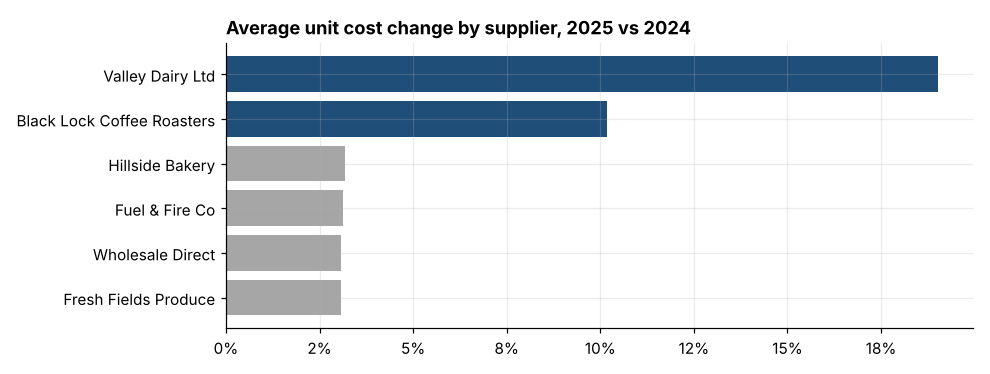

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.4))
sc = supplier_change.sort_values()
ax.barh(sc.index, sc.values, color=[CAFE if v > 8 else GREY for v in sc.values])
ax.set_title("Average unit cost change by supplier, 2025 vs 2024")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
fig.tight_layout(); fig.savefig(FIG / "04_supplier_cost_change.png", dpi=160); plt.show()

Four suppliers raised costs by about 3%, in line with the January price rise. Valley Dairy went up about 19% and the coffee roaster about 10%. Shelf prices did not follow, so the products those two supply lost margin: store dairy fell about ten points, and hot drinks and ice cream about three to four points.

## 5. Café operations: busy hours and staffing

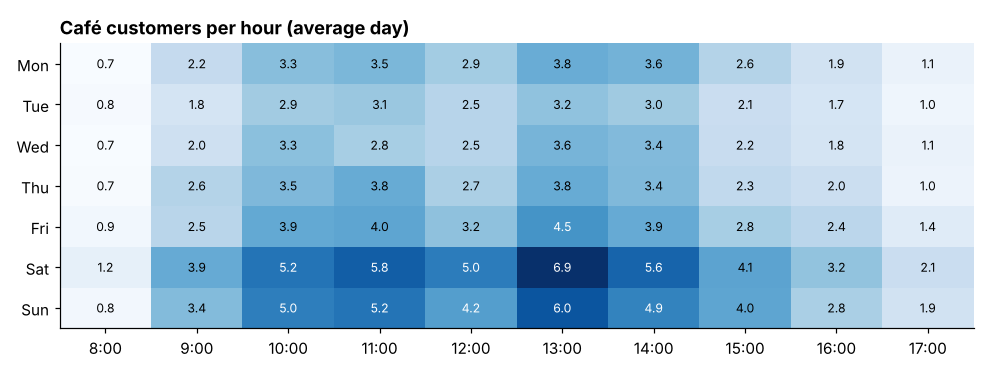

In [13]:
cafe = f[f["business_area"] == "Café"]
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
n_days = date.groupby("Day")["Date"].count()
heat = cafe.groupby(["Day", "hour"])["customer_id"].nunique().unstack("hour").reindex(days)
heat = heat.div(n_days.reindex(days), axis=0)

fig, ax = plt.subplots(figsize=(9, 3.4))
im = ax.imshow(heat.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(heat.shape[1])); ax.set_xticklabels([f"{h}:00" for h in heat.columns])
ax.set_yticks(range(7)); ax.set_yticklabels(days); ax.grid(False)
for i, j in itertools.product(range(heat.shape[0]), range(heat.shape[1])):
    v = heat.values[i, j]
    if not np.isnan(v):
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8, color="white" if v > heat.values[~np.isnan(heat.values)].max() * 0.6 else "black")
ax.set_title("Café customers per hour (average day)")
fig.tight_layout(); fig.savefig(FIG / "05_cafe_day_hour_heatmap.png", dpi=160); plt.show()

In [14]:
cafe_staff = staff.loc[staff["business_area"] == "Café", "staff_id"]
sh = shifts[shifts["staff_id"].isin(cafe_staff)].merge(date[["Date", "Day"]], left_on="date", right_on="Date")
staffing = pd.DataFrame({
    "customers_per_day": cafe.groupby("Day")["customer_id"].nunique() / n_days,
    "staff_hours_per_day": sh.groupby("Day")["hours"].sum() / n_days,
}).reindex(days)
staffing["customers_per_staff_hour"] = staffing["customers_per_day"] / staffing["staff_hours_per_day"]
staffing["vs_average_%"] = (staffing["customers_per_staff_hour"] / staffing["customers_per_staff_hour"].mean() - 1) * 100
staffing

,customers_per_day,staff_hours_per_day,customers_per_staff_hour,vs_average_%
Day,,,,
Mon,25.64,16.00,1.60,5.66
Tue,21.98,24.00,0.92,-39.61
Wed,23.32,24.00,0.97,-35.92
Thu,26.02,16.00,1.63,7.23
Fri,29.51,24.00,1.23,-18.93
Sat,42.89,16.00,2.68,76.77
Sun,38.14,24.00,1.59,4.80


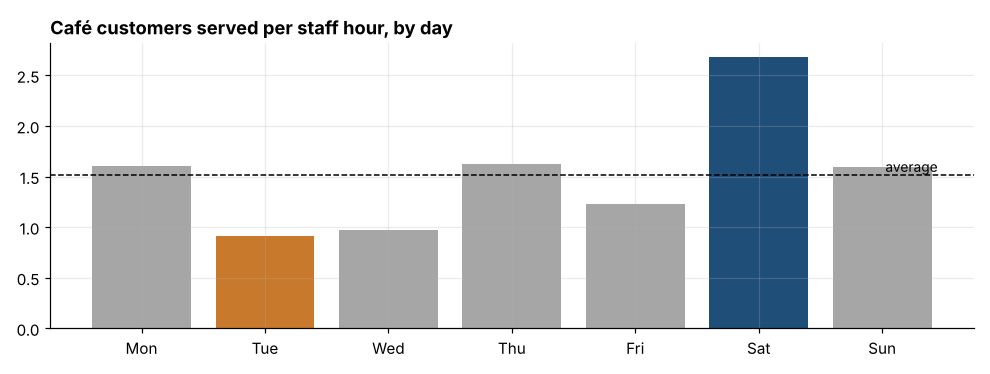

In [15]:
fig, ax = plt.subplots(figsize=(9, 3.4))
v = staffing["customers_per_staff_hour"]
ax.bar(days, v, color=[CAFE if x == v.max() else (STORE if x == v.min() else GREY) for x in v])
ax.axhline(v.mean(), color="black", ls="--", lw=1); ax.text(6.45, v.mean() + 0.03, "average", ha="right", fontsize=9)
ax.set_title("Café customers served per staff hour, by day")
fig.tight_layout(); fig.savefig(FIG / "06_cafe_customers_per_staff_hour.png", dpi=160); plt.show()

Saturday is the busiest café day (about 43 customers) but has only 16 staff hours, the same as a quiet Monday. Each staff hour on a Saturday handles 2.7 customers, about 77% above the weekly average. Tuesday and Wednesday are the quietest days and have 24 staff hours each. Moving one shift from Tuesday or Wednesday to Saturday would balance the rota without adding any wage cost.

## 6. Wastage

Wasted units are costed at the product's cost price.

In [16]:
w = wastage.merge(products, on="product_id").merge(date[["Date", "Day", "Year"]], left_on="date", right_on="Date")
w["waste_cost"] = w["quantity_wasted"] * w["cost_price"]
by_area = w.groupby(["business_area", "Year"])["waste_cost"].sum().unstack()
by_area

Year,2024,2025
business_area,,
Café,"3,040.72","3,219.74"
Store,"1,412.01","1,347.24"


In [17]:
wc = w[w["business_area"] == "Café"]
waste_day = pd.DataFrame({
    "units_per_day": wc.groupby("Day")["quantity_wasted"].sum() / n_days,
    "cost_per_day": wc.groupby("Day")["waste_cost"].sum() / n_days,
}).reindex(days)
other = waste_day.loc[["Tue", "Wed", "Thu", "Fri"], "units_per_day"].mean()
print(f"Monday café waste is {waste_day.loc['Mon', 'units_per_day'] / other:.1f}x the Tue-Fri average")
waste_day

Monday café waste is 2.1x the Tue-Fri average


,units_per_day,cost_per_day
Day,,
Mon,20.02,14.12
Tue,9.17,6.75
Wed,9.15,6.68
Thu,9.78,7.10
Fri,10.08,7.22
Sat,12.97,9.30
Sun,12.18,8.75


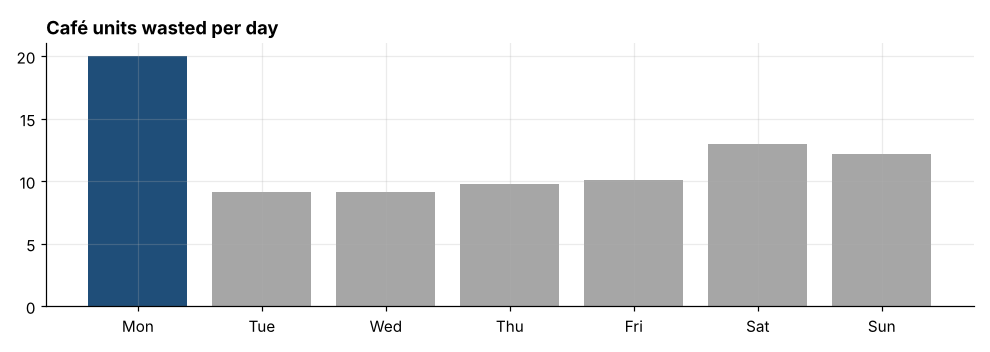

,units
reason,
Unsold end of day,7447
Damaged,552
Dropped,369
Not recorded,339


In [18]:
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(days, waste_day["units_per_day"], color=[CAFE if d == "Mon" else GREY for d in days])
ax.set_title("Café units wasted per day")
fig.tight_layout(); fig.savefig(FIG / "07_cafe_waste_by_day.png", dpi=160); plt.show()
wc.groupby("reason")["quantity_wasted"].sum().sort_values(ascending=False).to_frame("units")

In [19]:
top_waste = (wc[wc["Day"] == "Mon"].groupby("product_name")["quantity_wasted"].sum()
             .sort_values(ascending=False).head(5).to_frame("monday_units_wasted"))
top_waste

,monday_units_wasted
product_name,
Tuna Sandwich,421
Croissant,402
Fruit Scone,331
Chocolate Brownie,264
Welsh Cake,243


The café throws away about twice as much on a Monday as on any other weekday, almost all of it "unsold end of day" fresh food (sandwiches, croissants, scones). Monday has far fewer customers than the weekend (26 against 43 on Saturday), so the likely cause is that Monday's bake and prep is still sized for weekend trade. Cutting the Monday order for those five products is the quickest saving.

## 7. Weather and seasons

In [20]:
daily = f.groupby(["Date", "business_area", "Season", "SeasonNo", "Weather"])["revenue"].sum().reset_index()
wx = (daily[(daily["business_area"] == "Café") & (daily["Weather"] != "Not recorded")]
      .pivot_table(index=["SeasonNo", "Season"], columns="Weather", values="revenue", aggfunc="mean")
      [["Sunny", "Cloudy", "Rain", "Heavy Rain"]])
wx.round(0)

,Weather,Sunny,Cloudy,Rain,Heavy Rain
SeasonNo,Season,,,,
1,Winter,151.00,176.00,156.00,145.00
2,Spring,260.00,270.00,219.00,191.00
3,Summer,458.00,358.00,351.00,317.00
4,Autumn,248.00,248.00,215.00,196.00


Correlation between daily temperature and café revenue: 0.65


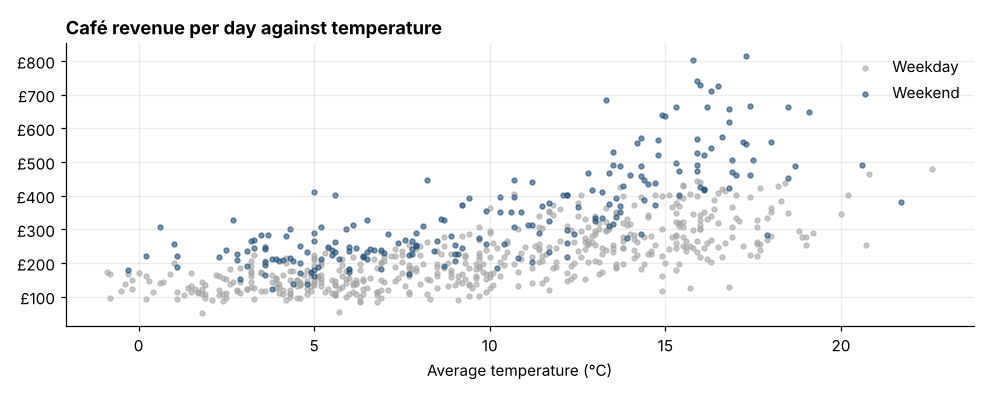

In [21]:
temp = (daily[daily["business_area"] == "Café"].merge(date[["Date", "avg_temp_c", "IsWeekend"]], on="Date")
        .dropna(subset=["avg_temp_c"]))
print(f"Correlation between daily temperature and café revenue: {temp['avg_temp_c'].corr(temp['revenue']):.2f}")
fig, ax = plt.subplots(figsize=(9, 3.6))
for label, color in [("Weekday", GREY), ("Weekend", CAFE)]:
    d = temp[temp["IsWeekend"] == label]
    ax.scatter(d["avg_temp_c"], d["revenue"], s=10, alpha=0.6, color=color, label=label)
ax.set_title("Café revenue per day against temperature"); ax.set_xlabel("Average temperature (°C)")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("£{x:,.0f}")); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "08_cafe_revenue_vs_temperature.png", dpi=160); plt.show()

Season matters more than weather: a summer day brings in two to three times a winter day. Weather only makes a big difference in summer, when a sunny day is worth about £140 more than a day of heavy rain. In winter the café takes roughly the same whatever the sky is doing. Practical use: staff and bake up for sunny summer forecasts, and do not bother adjusting in winter.

## 8. Outliers and basket analysis

### 8.1 Outliers with the IQR rule

The six `Suspicious` lines were found with the interquartile range rule on quantity. Almost every line is a quantity of 1, so the upper fence is very low and judgement is needed: quantities of 2 to 4 are normal shopping, quantities of 120 to 200 on one till line are keying errors.

In [22]:
q = sales["quantity"]
q1_, q3_ = q.quantile([0.25, 0.75])
print(f"Q1 = {q1_}, Q3 = {q3_}, upper fence = {q3_ + 1.5 * (q3_ - q1_)}")
sales[sales["line_type"] == "Suspicious"].merge(products[["product_id", "product_name"]], on="product_id")[
    ["date", "transaction_id", "product_name", "quantity", "unit_price"]]

Q1 = 1.0, Q3 = 1.0, upper fence = 1.0


,date,transaction_id,product_name,quantity,unit_price
0,2024-07-20,T111214,Salted Butter 250g,200,2.45
1,2024-08-07,T112600,Soft Drink Can,150,1.25
2,2024-10-12,T117041,Bottled Water 500ml,200,1.00
3,2025-02-13,T122721,Americano,120,2.80
4,2025-05-16,T127546,Hot Chocolate,200,3.20
5,2025-09-24,T137068,Dog Treats,120,2.60


In [23]:
effect = sales.assign(revenue=sales["quantity"] * sales["unit_price"]).groupby("line_type")["revenue"].agg(["count", "sum"])
effect

,count,sum
line_type,,
Refund,115,-408.15
Sale,76705,"275,405.59"
Suspicious,6,"2,165.50"
Zero,30,0.00


### 8.2 What sells together in the café?

In [24]:
basket = cafe[cafe["quantity"] > 0].groupby("transaction_id")["product_name"].apply(lambda s: sorted(set(s)))
n_baskets = len(basket)
pairs = pd.Series([p for items in basket if len(items) > 1 for p in itertools.combinations(items, 2)]).value_counts()
item_share = cafe[cafe["quantity"] > 0].groupby("product_name")["transaction_id"].nunique() / n_baskets
top = pairs.head(8).to_frame("baskets")
top["support_%"] = top["baskets"] / n_baskets * 100
top["lift"] = [top.loc[[p], "baskets"].iloc[0] / n_baskets / (item_share[p[0]] * item_share[p[1]]) for p in top.index]
print(f"{n_baskets:,} café baskets, {(basket.map(len) > 1).mean():.0%} contain more than one product")
top

21,652 café baskets, 66% contain more than one product


,baskets,support_%,lift
"(Americano, Latte)",730,3.37,0.82
"(Cappuccino, Latte)",656,3.03,0.80
"(Americano, Cappuccino)",520,2.40,0.75
"(Flat White, Latte)",444,2.05,0.82
"(Latte, Pot of Tea)",433,2.00,0.75
"(Bacon Roll, Latte)",426,1.97,0.77
"(Latte, Welsh Cake)",401,1.85,0.85
"(Fruit Scone, Latte)",397,1.83,0.85


The most common pairs are simply the best sellers appearing together (two coffees in one order). Every lift value is below 1, which means these pairs occur no more often than chance would predict. So there is no hidden "people who buy X also buy Y" pattern to build a meal deal around. Reporting a negative result is still useful: it stops Gwen spending money on a bundle that the data does not support.

## Summary of the numbers

Saved to `outputs/key_numbers.csv` so the README, the SQL results and the dashboard can be checked against one file.

In [25]:
key = pd.Series({
    "Revenue 2024 (£)": kpi.loc[2024, "revenue"],
    "Revenue 2025 (£)": kpi.loc[2025, "revenue"],
    "Revenue YoY %": kpi.loc[2025, "revenue_yoy_%"],
    "Gross margin 2025 %": kpi.loc[2025, "gross_margin_%"],
    "Customers 2025": kpi.loc[2025, "customers"],
    "Average spend 2025 (£)": kpi.loc[2025, "avg_spend"],
    "Café revenue YoY %": split.loc["Café", "revenue_yoy_%"],
    "Store revenue YoY %": split.loc["Store", "revenue_yoy_%"],
    "Café customers YoY %": split.loc["Café", "customers_yoy_%"],
    "Store customers YoY %": split.loc["Store", "customers_yoy_%"],
    "Store customers YoY % Jan-Mar": (q1[2025] / q1[2024] - 1) * 100,
    "Store customers YoY % Apr-Dec": (rest[2025] / rest[2024] - 1) * 100,
    "Valley Dairy unit cost change %": supplier_change["Valley Dairy Ltd"],
    "Coffee roaster unit cost change %": supplier_change["Black Lock Coffee Roasters"],
    "Store dairy margin 2024 %": margin.loc[("Store", "Dairy"), "margin_2024_%"],
    "Store dairy margin 2025 %": margin.loc[("Store", "Dairy"), "margin_2025_%"],
    "Café margin 2024 %": split.loc["Café", "margin_2024_%"],
    "Café margin 2025 %": split.loc["Café", "margin_2025_%"],
    "Monday café waste vs Tue-Fri (x)": waste_day.loc["Mon", "units_per_day"] / other,
    "Café waste cost 2 years (£)": by_area.loc["Café"].sum(),
    "Sat café customers per staff hour": staffing.loc["Sat", "customers_per_staff_hour"],
    "Tue café customers per staff hour": staffing.loc["Tue", "customers_per_staff_hour"],
}).round(2)
key.to_frame("value").to_csv(ROOT / "outputs" / "key_numbers.csv", index_label="metric")
key.to_frame("value")

,value
Revenue 2024 (£),"133,993.94"
Revenue 2025 (£),"141,003.50"
Revenue YoY %,5.23
Gross margin 2025 %,66.94
Customers 2025,"20,890.00"
Average spend 2025 (£),6.75
Café revenue YoY %,12.45
Store revenue YoY %,-8.26
Café customers YoY %,11.96
Store customers YoY %,-10.96
